In [1]:
pip install pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("retail_customer_sales_dataset.csv")

print("Dataset loaded successfully!")

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset loaded successfully!

First 5 Records:


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.0,Male,62828.52,West,Gujarat,Surat,...,887.94,0.32,1811.40,1204.47,606.93,Debit Card,Standard,3.0,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.0,Male,50952.64,North,Haryana,Gurugram,...,14309.96,0.18,23468.33,17137.06,6331.27,Credit Card,Standard,3.0,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.0,Male,60476.00,East,Jharkhand,Ranchi,...,710.95,0.09,2587.86,1577.83,1010.03,Debit Card,Express,3.0,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.0,Male,41516.94,West,Gujarat,Surat,...,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.0,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.0,Female,95727.49,north,Haryana,Gurugram,...,10542.13,0.21,8328.28,5528.47,2799.81,UPI,Express,1.0,Low,No



Dataset Shape: (7084, 24)

Column Names:
['Transaction_ID', 'Customer_ID', 'Order_Date', 'Delivery_Date', 'Age', 'Gender', 'Income', 'Region', 'State', 'City', 'Customer_Segment', 'Product_Category', 'Product', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit', 'Payment_Method', 'Delivery_Mode', 'Customer_Rating', 'Satisfaction_Level', 'Returned']


In [4]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nNumber of Missing Values:")
print(df.isnull().sum())

print("\nNumber of Duplicate Records:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7084 entries, 0 to 7083
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      7084 non-null   str    
 1   Customer_ID         7084 non-null   str    
 2   Order_Date          7084 non-null   str    
 3   Delivery_Date       6978 non-null   str    
 4   Age                 6942 non-null   float64
 5   Gender              7084 non-null   str    
 6   Income              6831 non-null   float64
 7   Region              7084 non-null   str    
 8   State               7084 non-null   str    
 9   City                7084 non-null   str    
 10  Customer_Segment    7084 non-null   str    
 11  Product_Category    7084 non-null   str    
 12  Product             7084 non-null   str    
 13  Quantity            7084 non-null   int64  
 14  Unit_Price          7084 non-null   float64
 15  Discount            7013 non-null   float64
 

,Age,Income,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Customer_Rating
count,6942.000000,6.831000e+03,7084.00000,7084.000000,7013.000000,7084.000000,7084.000000,7084.000000,6656.000000
mean,36.234659,5.502381e+04,3.00847,4520.135232,0.200864,10942.867178,7360.466942,3582.400236,3.090595
std,15.735618,3.718343e+04,1.41129,4891.123919,0.121249,14504.750762,9849.348506,4912.636593,1.011457
min,-12.000000,1.500000e+04,1.00000,51.530000,-0.200000,28.700000,19.530000,9.170000,1.000000
25%,29.000000,3.705703e+04,2.00000,896.977500,0.110000,1816.572500,1214.417500,574.082500,2.000000
50%,36.000000,4.889751e+04,3.00000,2265.700000,0.180000,4835.195000,3233.080000,1530.365000,3.000000
75%,43.000000,6.539597e+04,4.00000,7224.157500,0.270000,14066.117500,9468.867500,4528.592500,4.000000
max,999.000000,1.750890e+06,10.00000,19989.990000,2.000000,122950.970000,81532.800000,47233.610000,5.000000



Number of Missing Values:
Transaction_ID          0
Customer_ID             0
Order_Date              0
Delivery_Date         106
Age                   142
Gender                  0
Income                253
Region                  0
State                   0
City                    0
Customer_Segment        0
Product_Category        0
Product                 0
Quantity                0
Unit_Price              0
Discount               71
Sales                   0
Cost                    0
Profit                  0
Payment_Method          0
Delivery_Mode           0
Customer_Rating       428
Satisfaction_Level    179
Returned                0
dtype: int64

Number of Duplicate Records:
61


In [5]:
df = df.drop_duplicates()

print("Duplicate records removed.")
print("Updated Shape:", df.shape)

Duplicate records removed.
Updated Shape: (7023, 24)


In [6]:
df.columns = df.columns.str.strip()

print("Column names cleaned.")

Column names cleaned.


In [7]:
# Identify numerical and categorical columns
numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

# Fill numerical missing values with median
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode
for col in categorical_cols:
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled.")
print(df.isnull().sum())

Missing values handled.
Transaction_ID        0
Customer_ID           0
Order_Date            0
Delivery_Date         0
Age                   0
Gender                0
Income                0
Region                0
State                 0
City                  0
Customer_Segment      0
Product_Category      0
Product               0
Quantity              0
Unit_Price            0
Discount              0
Sales                 0
Cost                  0
Profit                0
Payment_Method        0
Delivery_Mode         0
Customer_Rating       0
Satisfaction_Level    0
Returned              0
dtype: int64


C:\Users\hp\AppData\Local\Temp\ipykernel_16892\2761530478.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


In [8]:
date_columns = ["Order_Date", "Delivery_Date"]

for col in date_columns:
    if col in df.columns:
        df[col] = df[col].apply(
            lambda x: pd.to_datetime(x, errors="coerce", dayfirst=True)
        )

print("Date columns converted successfully.")

C:\Users\hp\AppData\Local\Temp\ipykernel_16892\262590148.py:6: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  lambda x: pd.to_datetime(x, errors="coerce", dayfirst=True)


C:\Users\hp\AppData\Local\Temp\ipykernel_16892\262590148.py:6: UserWarning: Parsing dates in %m-%d-%Y format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  lambda x: pd.to_datetime(x, errors="coerce", dayfirst=True)
C:\Users\hp\AppData\Local\Temp\ipykernel_16892\262590148.py:6: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  lambda x: pd.to_datetime(x, errors="coerce", dayfirst=True)
C:\Users\hp\AppData\Local\Temp\ipykernel_16892\262590148.py:6: UserWarning: Parsing dates in %m-%d-%Y format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  lambda x: pd.to_datetime(x, errors="coerce", dayfirst=True)


Date columns converted successfully.


In [9]:
categorical_columns = [
    "Gender", "Region", "State", "City",
    "Customer_Segment", "Product_Category",
    "Product", "Payment_Method",
    "Delivery_Mode", "Satisfaction_Level"
]

for col in categorical_columns:
    if col in df.columns:
        df[col] = (
            df[col].astype("string")
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
            .str.title()
        )

print("Categorical values standardized.")

Categorical values standardized.


In [10]:
# Correct invalid age values
if "Age" in df.columns:
    df.loc[(df["Age"] < 0) | (df["Age"] > 100), "Age"] = np.nan
    df["Age"] = df["Age"].fillna(df["Age"].median())

# Correct invalid quantity
if "Quantity" in df.columns:
    df.loc[df["Quantity"] <= 0, "Quantity"] = np.nan
    df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())

# Correct invalid unit prices
if "Unit_Price" in df.columns:
    df.loc[df["Unit_Price"] < 0, "Unit_Price"] = np.nan
    df["Unit_Price"] = df["Unit_Price"].fillna(
        df["Unit_Price"].median()
    )

# Customer rating should be between 1 and 5
if "Customer_Rating" in df.columns:
    df.loc[
        ~df["Customer_Rating"].between(1, 5),
        "Customer_Rating"
    ] = np.nan

    df["Customer_Rating"] = df["Customer_Rating"].fillna(
        df["Customer_Rating"].median()
    )

print("Invalid numerical values handled.")

Invalid numerical values handled.


In [11]:
print("Cleaned Dataset:")
display(df.head())

print("\nRemaining Missing Values:")
print(df.isnull().sum())

print("\nRemaining Duplicate Records:")
print(df.duplicated().sum())

print("\nUpdated Dataset Shape:")
print(df.shape)

Cleaned Dataset:


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.0,Male,62828.52,West,Gujarat,Surat,...,887.94,0.32,1811.40,1204.47,606.93,Debit Card,Standard,3.0,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-04-10,42.0,Male,50952.64,North,Haryana,Gurugram,...,14309.96,0.18,23468.33,17137.06,6331.27,Credit Card,Standard,3.0,High,No
2,TXN202714,CUST11352,2023-12-01,2023-01-20,41.0,Male,60476.00,East,Jharkhand,Ranchi,...,710.95,0.09,2587.86,1577.83,1010.03,Debit Card,Express,3.0,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-10-06,33.0,Male,41516.94,West,Gujarat,Surat,...,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.0,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.0,Female,95727.49,North,Haryana,Gurugram,...,10542.13,0.21,8328.28,5528.47,2799.81,Upi,Express,1.0,Low,No



Remaining Missing Values:
Transaction_ID        0
Customer_ID           0
Order_Date            0
Delivery_Date         0
Age                   0
Gender                0
Income                0
Region                0
State                 0
City                  0
Customer_Segment      0
Product_Category      0
Product               0
Quantity              0
Unit_Price            0
Discount              0
Sales                 0
Cost                  0
Profit                0
Payment_Method        0
Delivery_Mode         0
Customer_Rating       0
Satisfaction_Level    0
Returned              0
dtype: int64

Remaining Duplicate Records:
16

Updated Dataset Shape:
(7023, 24)


In [12]:
df.to_csv("cleaned_retail_sales_dataset.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [13]:
if "Order_Date" in df.columns:
    df["Year"] = df["Order_Date"].dt.year
    df["Month"] = df["Order_Date"].dt.month
    df["Month_Name"] = df["Order_Date"].dt.month_name()
    df["Day"] = df["Order_Date"].dt.day

print("New date features created.")

display(df.head())

New date features created.


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned,Year,Month,Month_Name,Day
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.0,Male,62828.52,West,Gujarat,Surat,...,606.93,Debit Card,Standard,3.0,Low,No,2023,12,December,19
1,TXN201247,CUST10916,2023-09-30,2023-04-10,42.0,Male,50952.64,North,Haryana,Gurugram,...,6331.27,Credit Card,Standard,3.0,High,No,2023,9,September,30
2,TXN202714,CUST11352,2023-12-01,2023-01-20,41.0,Male,60476.00,East,Jharkhand,Ranchi,...,1010.03,Debit Card,Express,3.0,Medium,No,2023,12,December,1
3,TXN206797,CUST11551,2024-06-06,2024-10-06,33.0,Male,41516.94,West,Gujarat,Surat,...,320.97,Debit Card,Standard,3.0,Medium,No,2024,6,June,6
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.0,Female,95727.49,North,Haryana,Gurugram,...,2799.81,Upi,Express,1.0,Low,No,2024,9,September,23


In [14]:
total_sales = df["Sales"].sum()

print("Total Sales:", total_sales)

Total Sales: 76959144.10999998


In [15]:
total_profit = df["Profit"].sum()

print("Total Profit:", total_profit)

Total Profit: 25194341.15


In [16]:
print("Total Transactions:", df["Transaction_ID"].nunique())

Total Transactions: 7000


In [17]:
print("Total Customers:", df["Customer_ID"].nunique())
print("Average Sales:", df["Sales"].mean())
category_sales = df.groupby("Product_Category")["Sales"].sum()

print(category_sales.sort_values(ascending=False))
region_sales = df.groupby("Region")["Sales"].sum()

print(region_sales.sort_values(ascending=False))
payment_analysis = df["Payment_Method"].value_counts()

print(payment_analysis)

Total Customers: 1576
Average Sales: 10958.158067777302
Product_Category
Electronics        37747851.12
Furniture          26126953.65
Clothing            7822458.53
Grocery             2691759.69
Office Supplies     2570121.12
Name: Sales, dtype: float64
Region
East     20039030.62
West     19819530.26
South    18644536.67
North    17964589.93
Sth        334996.61
Nort       156460.02
Name: Sales, dtype: float64
Payment_Method
Net Banking         1436
Debit Card          1423
Cash On Delivery    1413
Upi                 1412
Credit Card         1339
Name: count, dtype: Int64


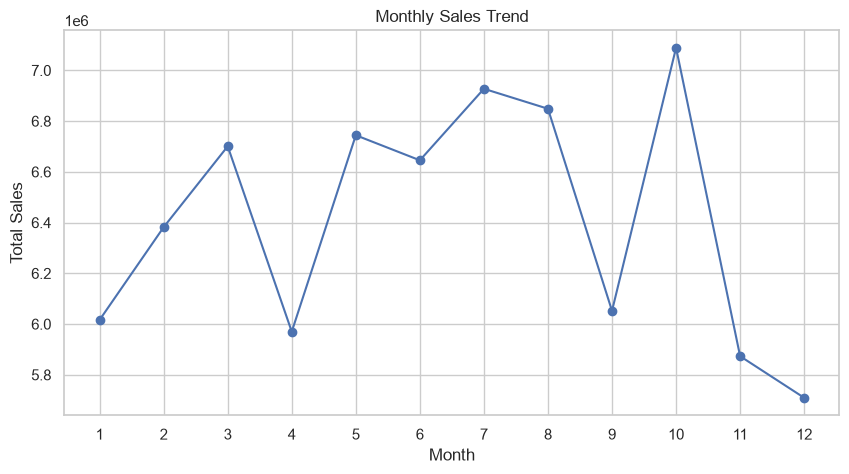

In [18]:
monthly_sales = df.groupby("Month")["Sales"].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

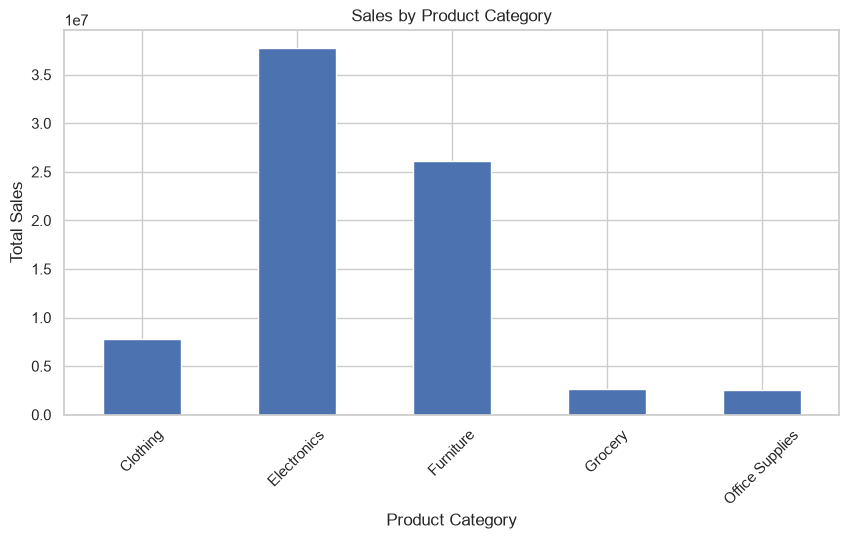

In [19]:
category_sales = df.groupby("Product_Category")["Sales"].sum()

category_sales.plot(kind="bar", figsize=(10, 5))

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

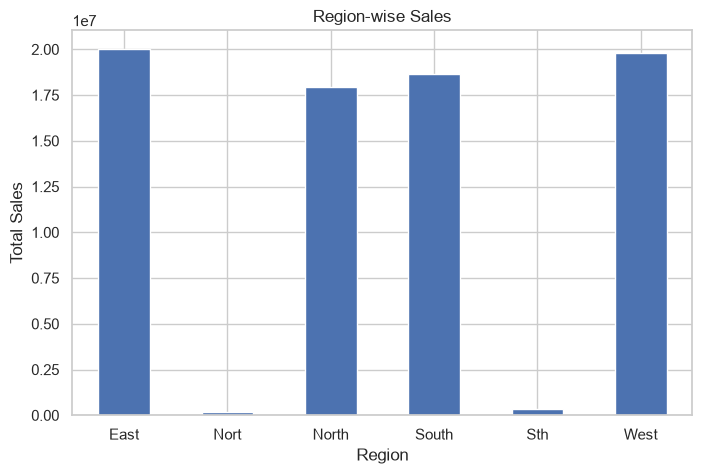

In [20]:
region_sales = df.groupby("Region")["Sales"].sum()

region_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Region-wise Sales")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

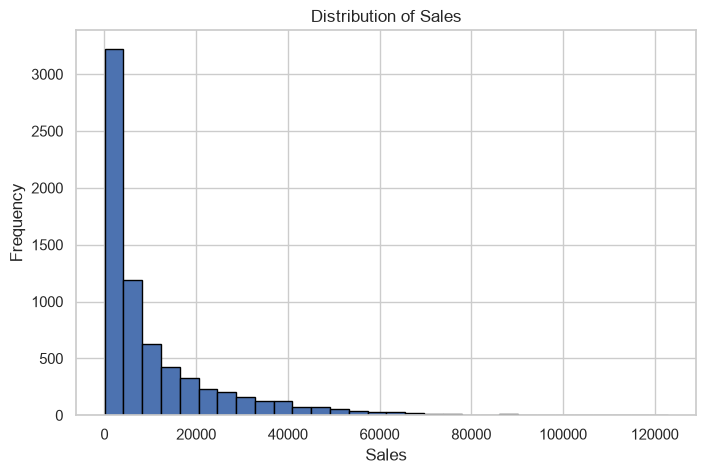

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(df["Sales"], bins=30, edgecolor="black")

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

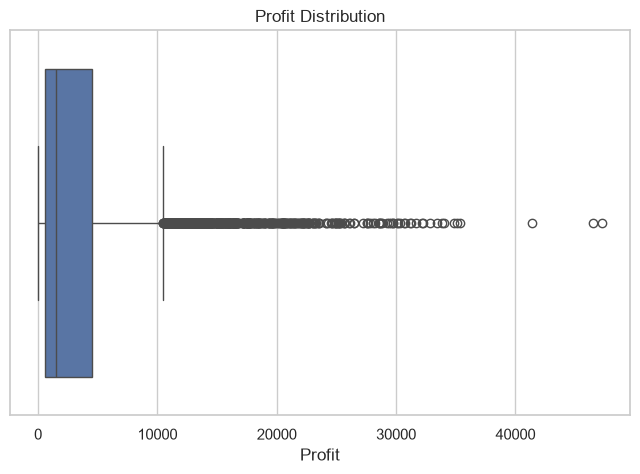

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Profit"])

plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.show()

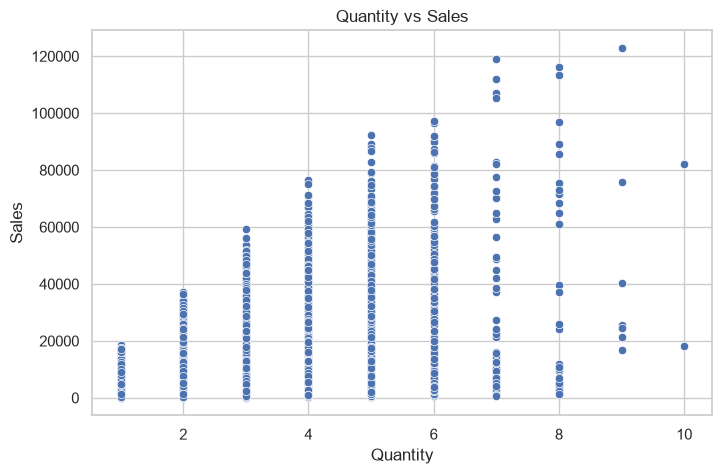

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Sales"
)

plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.show()

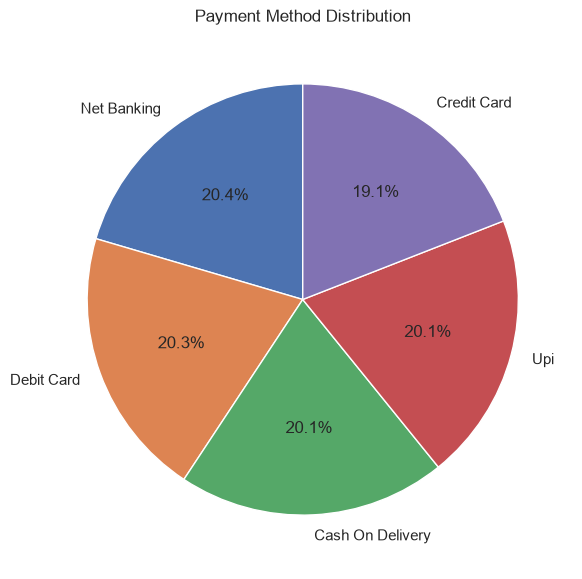

In [24]:
payment_counts = df["Payment_Method"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Payment Method Distribution")
plt.show()

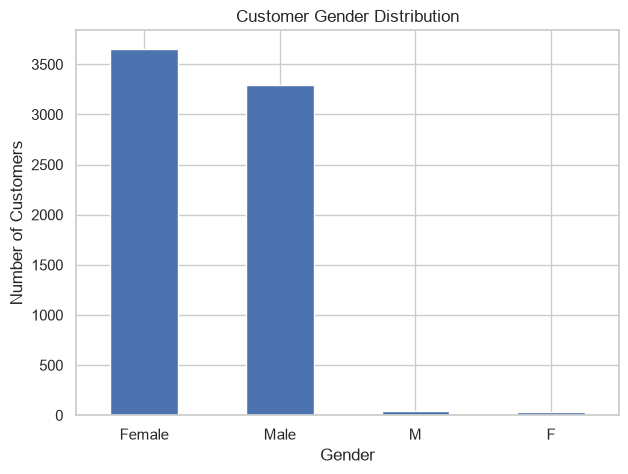

In [25]:
gender_counts = df["Gender"].value_counts()

gender_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

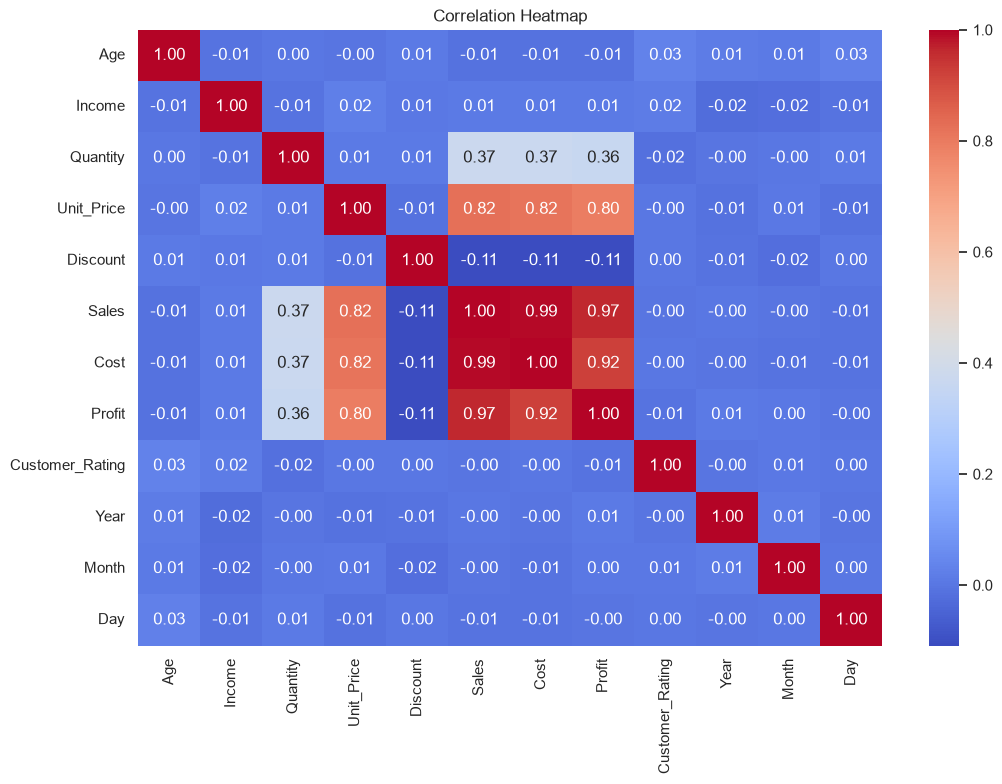

In [26]:
numeric_data = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

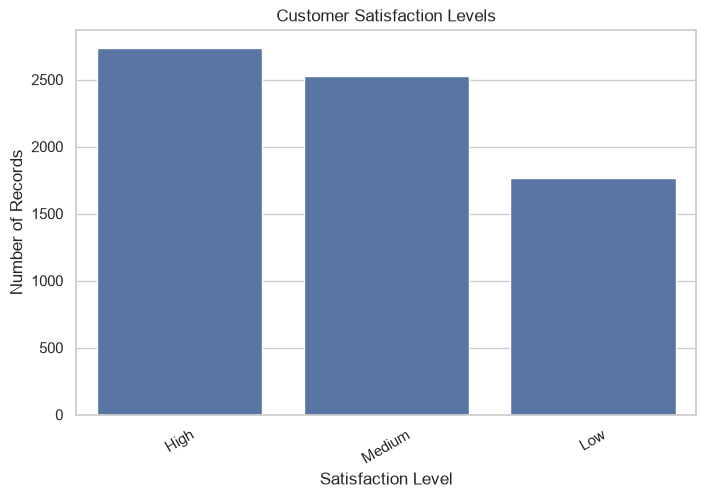

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Satisfaction_Level",
    order=df["Satisfaction_Level"].value_counts().index
)

plt.title("Customer Satisfaction Levels")
plt.xlabel("Satisfaction Level")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.show()

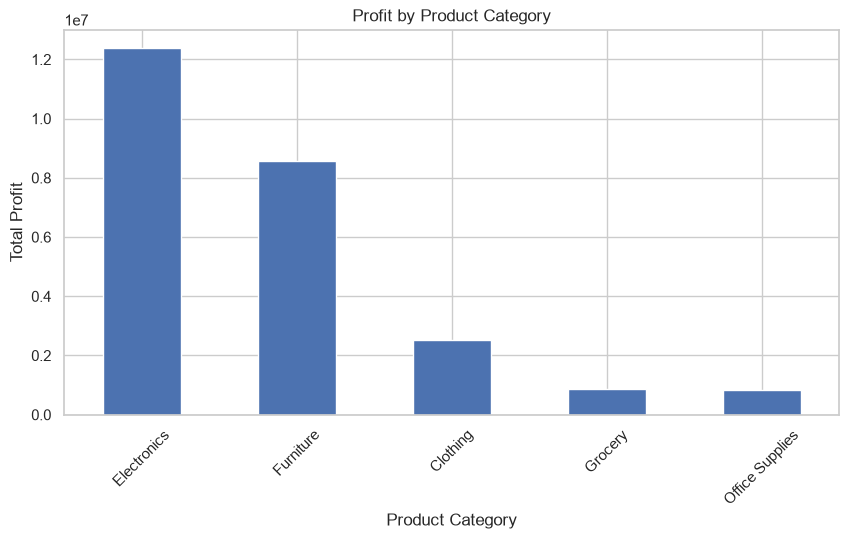

In [28]:
product_profit = (
    df.groupby("Product_Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

product_profit.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.show()

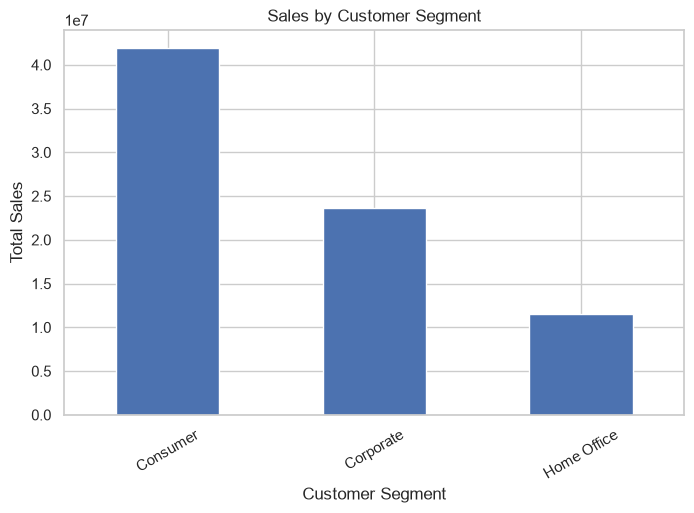

In [29]:
segment_sales = df.groupby("Customer_Segment")["Sales"].sum()

segment_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.show()